In [ ]:
from ultralytics import YOLO
import json
import shutil
from pathlib import Path
from collections import defaultdict
import yaml
import torch
from IPython.display import display, Image
import matplotlib.pyplot as plt
import cv2
import time
import pandas as pd
import numpy as np
import joblib
from skimage.feature import hog
from skimage.transform import resize
from PIL import Image as PILImage


In [ ]:
PROJECT_DIR = Path(
    r"C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection"
)

COCO_DIR = PROJECT_DIR / "data" / "processed"
YOLO_DIR = PROJECT_DIR / "data" / "yolo"

In [ ]:
# Define the five packaging and meat-presentation defect classes.
class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# Map COCO category IDs (1–5) to consecutive YOLO IDs (0–4).
# The unused COCO category ID 0 is excluded.
category_mapping = {
    1: 0,
    2: 1,
    3: 2,
    4: 3,
    5: 4
}

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 5
Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


In [ ]:
# Create separate image and label directories for each dataset split.
for split in ["train", "valid", "test"]:
    (YOLO_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (YOLO_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

for split in ["train", "valid", "test"]:
    annotation_path = COCO_DIR / split / "_annotations.coco.json"

    with annotation_path.open("r", encoding="utf-8") as file:
        coco = json.load(file)

    # Group annotations by image ID for efficient lookup.
    annotations_by_image = defaultdict(list)

    for ann in coco["annotations"]:
        annotations_by_image[ann["image_id"]].append(ann)

    image_count = 0
    annotation_count = 0

    for img in coco["images"]:
        source_image = COCO_DIR / split / img["file_name"]

        if not source_image.is_file():
            raise FileNotFoundError(source_image)

        # Preserve source images in a separate YOLO directory.
        destination_image = (
            YOLO_DIR / "images" / split / img["file_name"]
        )
        shutil.copy2(source_image, destination_image)

        image_width = img["width"]
        image_height = img["height"]

        label_path = (
            YOLO_DIR / "labels" / split /
            f"{Path(img['file_name']).stem}.txt"
        )

        labels = []

        for ann in annotations_by_image[img["id"]]:
            category_id = ann["category_id"]

            if category_id not in category_mapping:
                raise ValueError(
                    f"Unexpected category ID: {category_id}"
                )

            class_id = category_mapping[category_id]
            x, y, w, h = ann["bbox"]

            # Normalise COCO boxes to YOLO centre-coordinate format.
            x_center = (x + w / 2) / image_width
            y_center = (y + h / 2) / image_height
            w_norm = w / image_width
            h_norm = h / image_height

            labels.append(
                f"{class_id} "
                f"{x_center:.8f} {y_center:.8f} "
                f"{w_norm:.8f} {h_norm:.8f}"
            )

            annotation_count += 1

        # Empty label files represent images without annotated defects.
        label_path.write_text(
            "\n".join(labels),
            encoding="utf-8"
        )

        image_count += 1

    print(
        f"{split}: {image_count} images, "
        f"{annotation_count} annotations converted"
    )


train: 1741 images, 2201 annotations converted
valid: 114 images, 144 annotations converted
test: 76 images, 93 annotations converted


In [ ]:
# Verify YOLO image counts, label files, and annotation validity.
for split in ["train", "valid", "test"]:

    image_files = list(
        (YOLO_DIR / "images" / split).glob("*.jpg")
    )

    label_files = list(
        (YOLO_DIR / "labels" / split).glob("*.txt")
    )

    annotation_count = 0
    invalid_labels = 0

    for label_file in label_files:
        lines = label_file.read_text(
            encoding="utf-8"
        ).splitlines()

        for line in lines:
            values = line.split()

            try:
                numbers = [float(v) for v in values]
                class_id = int(values[0])

                # Check class IDs, normalised coordinates,
                # positive dimensions, and image boundaries.
                valid = (
                    len(numbers) == 5
                    and class_id in range(len(class_names))
                    and numbers[0] == class_id
                    and 0 <= numbers[1] <= 1
                    and 0 <= numbers[2] <= 1
                    and 0 < numbers[3] <= 1
                    and 0 < numbers[4] <= 1
                    and numbers[1] - numbers[3] / 2 >= -1e-6
                    and numbers[2] - numbers[4] / 2 >= -1e-6
                    and numbers[1] + numbers[3] / 2 <= 1 + 1e-6
                    and numbers[2] + numbers[4] / 2 <= 1 + 1e-6
                )

            except (ValueError, IndexError):
                valid = False

            if not valid:
                invalid_labels += 1

            annotation_count += 1

    # Report dataset completeness and invalid annotation counts.
    print(
        f"{split}: {len(image_files)} images, "
        f"{len(label_files)} label files, "
        f"{annotation_count} annotations, "
        f"{invalid_labels} invalid labels"
    )


train: 1741 images, 1741 label files, 2201 annotations, 0 invalid labels
valid: 114 images, 114 label files, 144 annotations, 0 invalid labels
test: 76 images, 76 label files, 93 annotations, 0 invalid labels


In [ ]:
# Define dataset paths and class names for YOLO training.
dataset_config = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = YOLO_DIR / "dataset.yaml"

# Save the configuration in YAML format for Ultralytics.
with yaml_path.open("w", encoding="utf-8") as file:
    yaml.safe_dump(
        dataset_config,
        file,
        sort_keys=False
    )

print("YOLO dataset configuration saved:", yaml_path)

In [ ]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = 0
else:
    print("Using CPU")
    device = "cpu"

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [ ]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 13.0


In [ ]:
# Load pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

# Train using the GPU
train_results = model.train(
    data=str(YOLO_DIR / "dataset.yaml"),
    epochs=20,
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    project=str(PROJECT_DIR / "results" / "yolo"),
    name="initial_training",
    seed=42,
    plots=True
)

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, mu

Results directory: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\yolo\initial_training-2
Best model: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\yolo\initial_training-2\weights\best.pt


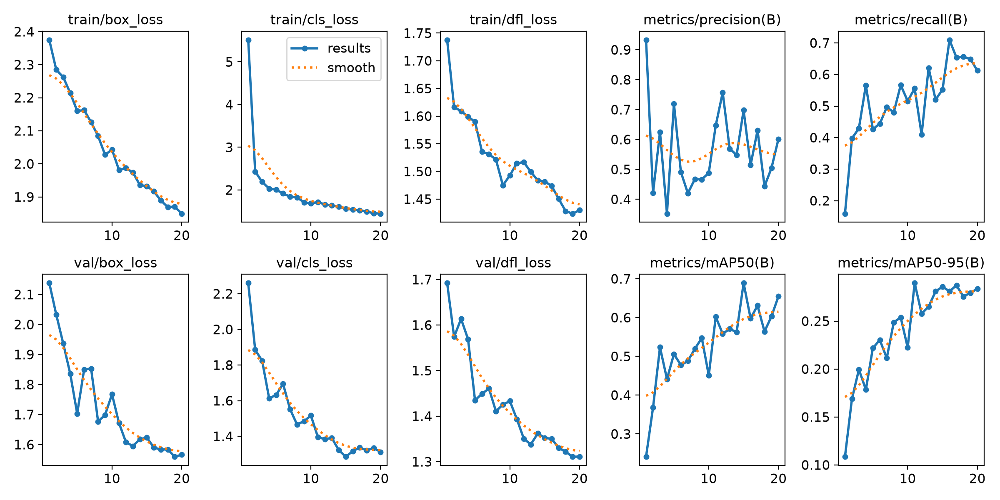

In [ ]:
run_dir = Path(model.trainer.save_dir)

print("Results directory:", run_dir)
print("Best model:", run_dir / "weights" / "best.pt")

results_plot = run_dir / "results.png"

if results_plot.exists():
    display(Image(filename=str(results_plot)))

In [10]:
# Load the best trained model
best_model = YOLO(str(run_dir / "weights" / "best.pt"))

# Evaluate on validation data
metrics = best_model.val(
    data=str(YOLO_DIR / "dataset.yaml"),
    split="val",
    device=0,
    plots=True
)

print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
print(f"mAP@0.5: {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2119.0±753.5 MB/s, size: 240.3 KB)
val: Scanning C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\labels\valid.cache... 114 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.0s/it 16.3s0.3s2
                   all        114        144      0.646      0.556      0.603      0.291
            loose-meat          5          5      0.804        0.6      0.746      0.293
       packaging-error         37         57      0.533     0.0702      0.224     0.0779
          twisted-meat          4          5      0.561        0.8      0.693      0.368
              unsealed         75         77      0.687    


0: 480x640 1 unsealed, 22.9ms
1: 480x640 2 unsealeds, 22.9ms
2: 480x640 (no detections), 22.9ms
3: 480x640 (no detections), 22.9ms
4: 480x640 (no detections), 22.9ms
Speed: 2.9ms preprocess, 22.9ms inference, 0.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\yolo\sample_predictions


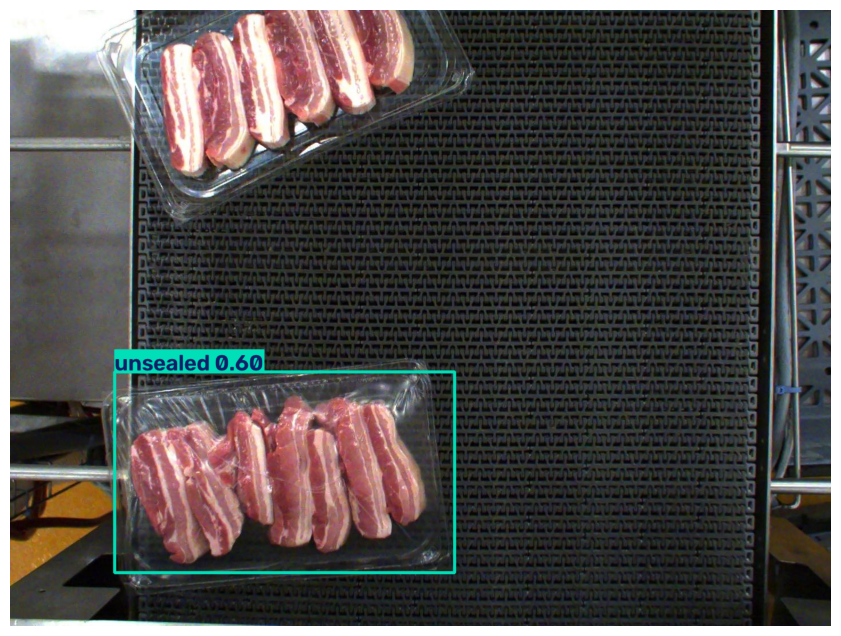

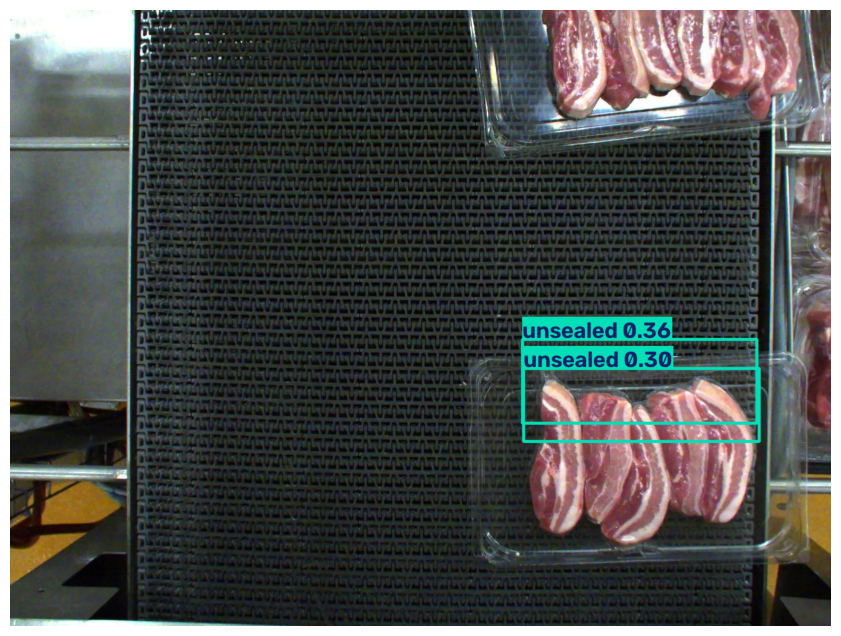

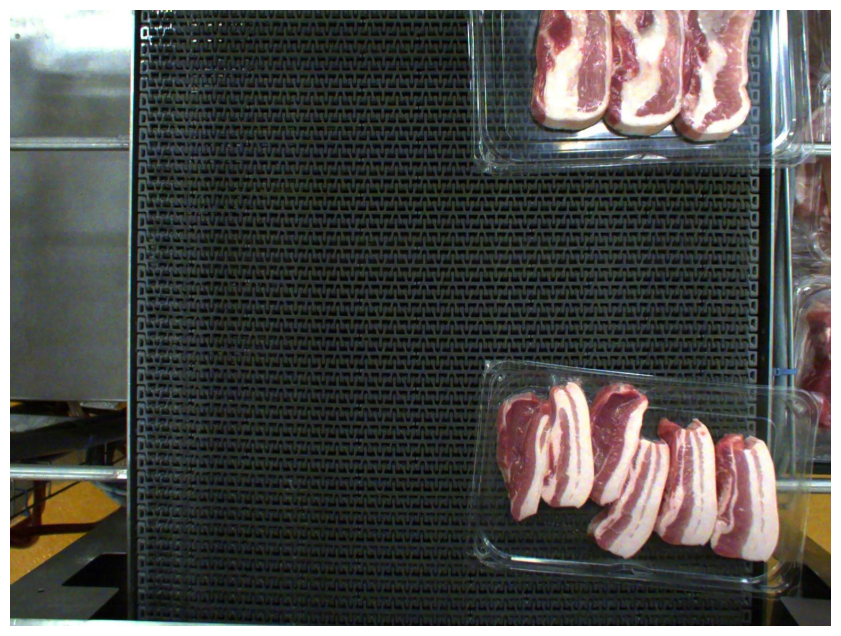

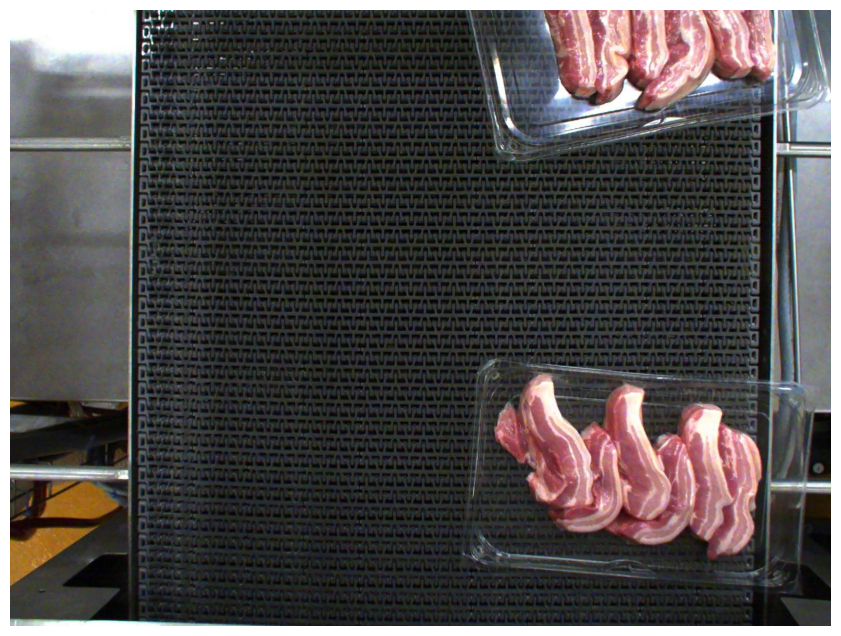

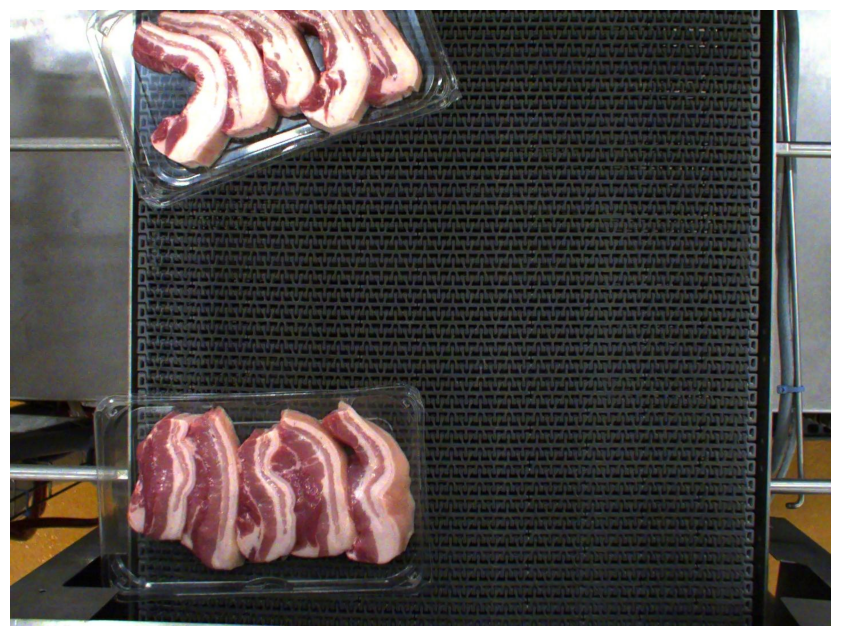

In [ ]:
# Load the best checkpoint from the initial YOLO training run.
best_model = YOLO(str(run_dir / "weights" / "best.pt"))

# Select five validation images for qualitative inspection.
validation_images = sorted(
    (YOLO_DIR / "images" / "valid").glob("*.jpg")
)

sample_images = validation_images[:5]

# Predict defects using a confidence threshold of 0.25.
predictions = best_model.predict(
    source=[str(p) for p in sample_images],
    conf=0.25,
    imgsz=640,
    device=0,
    save=True,
    project=str(PROJECT_DIR / "results" / "yolo"),
    name="sample_predictions",
    exist_ok=True
)

# Display predicted defect classes, scores and bounding boxes.
for prediction in predictions:
    annotated = prediction.plot()

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()


In [ ]:
# Start from the best model from the initial experiment
improved_model = YOLO(
    str(run_dir / "weights" / "best.pt")
)

# Additional training
improved_results = improved_model.train(
    data=str(YOLO_DIR / "dataset.yaml"),
    epochs=20,
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    project=str(PROJECT_DIR / "results" / "yolo"),
    name="extended_training",
    seed=42,
    plots=True
)

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork

In [ ]:
improved_dir = Path(improved_model.trainer.save_dir)

improved_best = YOLO(
    str(improved_dir / "weights" / "best.pt")
)

improved_metrics = improved_best.val(
    data=str(YOLO_DIR / "dataset.yaml"),
    split="val",
    device=0,
    plots=True
)

print(f"Precision: {improved_metrics.box.mp:.4f}")
print(f"Recall: {improved_metrics.box.mr:.4f}")
print(f"mAP@0.5: {improved_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {improved_metrics.box.map:.4f}")

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2108.5±715.1 MB/s, size: 240.3 KB)
val: Scanning C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\labels\valid.cache... 114 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 13.1s/it 1:45.2s:25
                   all        114        144      0.844      0.597      0.721       0.34
            loose-meat          5          5      0.847        0.6      0.795      0.296
       packaging-error         37         57          1       0.11      0.373      0.131
          twisted-meat          4          5      0.632          1      0.862      0.413
              unsealed         75         77      0.897   

Validation directory: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\runs\detect\val-2


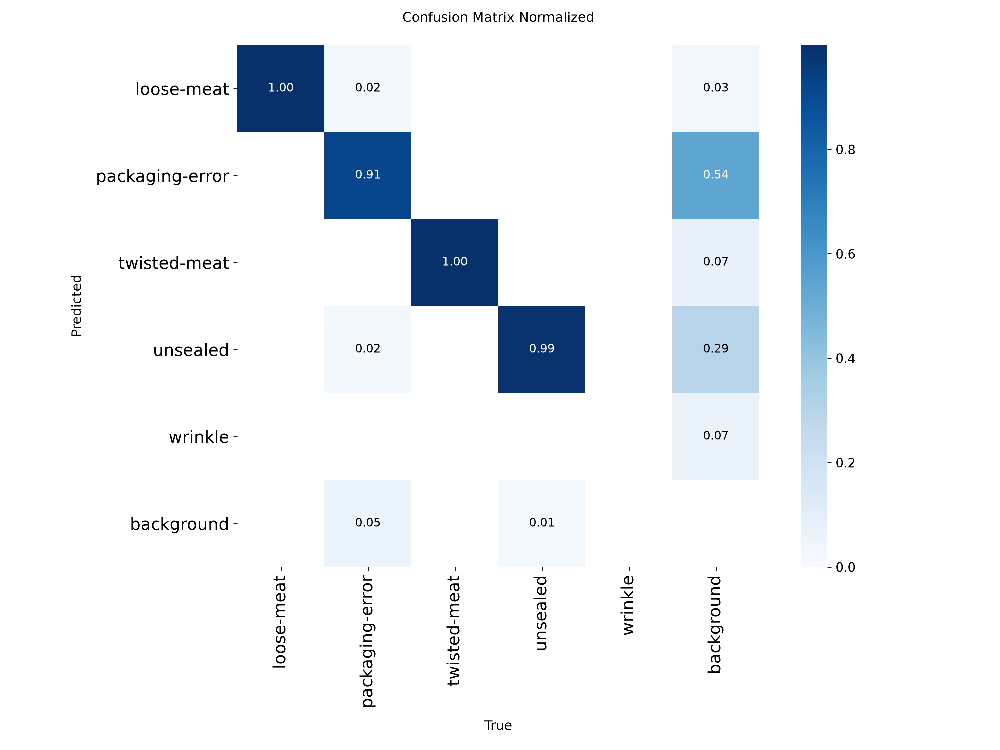

In [ ]:
validation_dir = Path(
    improved_metrics.save_dir
)

confusion_matrix_path = (
    validation_dir / "confusion_matrix_normalized.png"
)

print("Validation directory:", validation_dir)

if confusion_matrix_path.exists():
    display(
        Image(filename=str(confusion_matrix_path))
    )
else:
    print("Confusion matrix not found.")

In [ ]:
# Evaluate the precision–recall trade-off at different confidence thresholds.
confidence_thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

threshold_results = []

for conf in confidence_thresholds:

    # Evaluate the extended model on the same validation dataset.
    metrics = improved_best.val(
        data=str(YOLO_DIR / "dataset.yaml"),
        split="val",
        conf=conf,
        iou=0.7,
        device=0,
        plots=False,
        verbose=False
    )

    threshold_results.append({
        "Confidence": conf,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map
    })

# Summarise detection performance across confidence thresholds.
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)


Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 1.5±0.5 ms, read: 114.3±46.9 MB/s, size: 237.0 KB)
val: Scanning C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\labels\valid.cache... 114 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.5s/it 27.7s0.1s27
                   all        114        144      0.844      0.597      0.685      0.321
Speed: 2.3ms preprocess, 5.1ms inference, 0.0ms loss, 1.6ms postprocess per image
Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1219.6

,Confidence,Precision,Recall,mAP50,mAP50-95
0,0.1,0.844022,0.597380,0.685138,0.320700
1,0.2,0.844022,0.597380,0.624992,0.296646
2,0.3,0.832020,0.601808,0.577144,0.271133
3,0.4,0.934748,0.514616,0.475842,0.230357
4,0.5,0.900362,0.293996,0.271385,0.146977
5,0.6,0.742857,0.164776,0.162321,0.108177


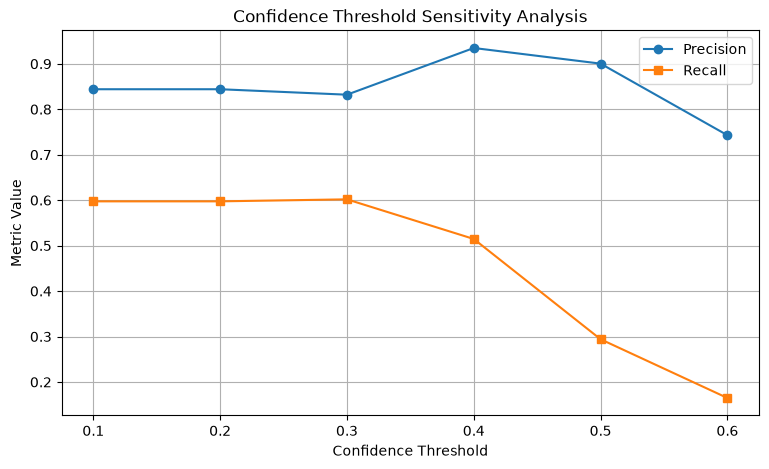

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Metric Value")
plt.title("Confidence Threshold Sensitivity Analysis")
plt.legend()
plt.grid(True)
plt.show()

,Metric,Initial YOLO,Extended YOLO,Improvement (percentage points)
0,Precision,0.6463,0.8440,19.77
1,Recall,0.5559,0.5974,4.15
2,mAP@0.5,0.6029,0.7213,11.84
3,mAP@0.5:0.95,0.2914,0.3400,4.86


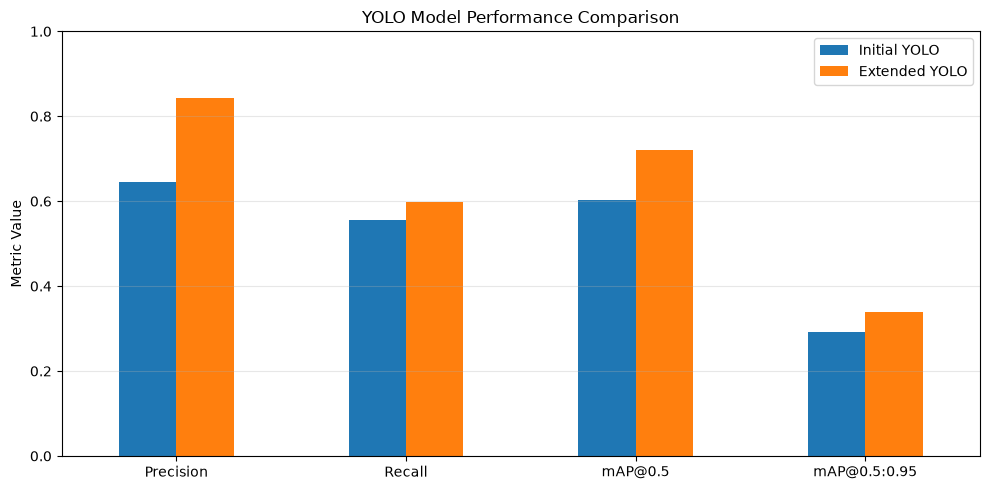

In [ ]:
# Compare validation performance before and after extended YOLO training.
comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.5",
        "mAP@0.5:0.95"
    ],
    "Initial YOLO": [
        0.6463,
        0.5559,
        0.6029,
        0.2914
    ],
    "Extended YOLO": [
        0.8440,
        0.5974,
        0.7213,
        0.3400
    ]
})

# Express performance changes in percentage points.
comparison["Improvement (percentage points)"] = (
    comparison["Extended YOLO"] -
    comparison["Initial YOLO"]
) * 100

display(comparison.round(4))

# Visualise improvements across the four evaluation metrics.
ax = comparison.set_index("Metric")[
    ["Initial YOLO", "Extended YOLO"]
].plot.bar(figsize=(10, 5))

plt.ylabel("Metric Value")
plt.xlabel("")
plt.title("YOLO Model Performance Comparison")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Load the best checkpoints from both training experiments.
initial_model = YOLO(
    str(run_dir / "weights" / "best.pt")
)

extended_model = YOLO(
    str(improved_dir / "weights" / "best.pt")
)

# Use identical test images for a consistent runtime comparison.
test_images = sorted(
    (YOLO_DIR / "images" / "test").glob("*.jpg")
)

print("Number of benchmark images:", len(test_images))


def benchmark_yolo(model, images, repetitions=3):
    """Measure YOLO inference time, throughput, and GPU memory.

    Args:
        model (YOLO): Trained Ultralytics YOLO model.
        images (list[Path]): Image paths used for benchmarking.
        repetitions (int): Number of timed runs. Defaults to 3.

    Returns:
        dict: Mean processing time per image, timing variation,
            throughput in FPS, and peak allocated GPU memory.
    """
    image_paths = [str(path) for path in images]

    # Warm up the model before collecting timing measurements.
    model.predict(
        source=image_paths[0],
        imgsz=640,
        conf=0.30,
        device=0,
        verbose=False
    )

    torch.cuda.synchronize()
    times = []

    # Reset peak memory tracking for this benchmark.
    torch.cuda.reset_peak_memory_stats(0)

    for _ in range(repetitions):

        start = time.perf_counter()

        model.predict(
            source=image_paths,
            imgsz=640,
            conf=0.30,
            batch=4,
            device=0,
            verbose=False
        )

        # Ensure GPU operations finish before recording elapsed time.
        torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        times.append(elapsed / len(images))

    return {
        "Mean time per image (ms)": np.mean(times) * 1000,
        "Std time per image (ms)": np.std(times) * 1000,
        "Throughput (FPS)": 1 / np.mean(times),
        "Peak GPU memory (MB)":
            torch.cuda.max_memory_allocated(0) / (1024 ** 2)
    }


# Benchmark both models using identical settings.
initial_benchmark = benchmark_yolo(
    initial_model, test_images
)

extended_benchmark = benchmark_yolo(
    extended_model, test_images
)

# Compare processing speed and peak GPU memory usage.
benchmark_df = pd.DataFrame(
    [initial_benchmark, extended_benchmark],
    index=["Initial YOLO", "Extended YOLO"]
)

display(benchmark_df.round(2))


Number of benchmark images: 76


,Mean time per image (ms),Std time per image (ms),Throughput (FPS),Peak GPU memory (MB)
Initial YOLO,22.72,4.89,44.01,1522.55
Extended YOLO,39.28,4.04,25.46,1531.79


In [22]:
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

benchmark_df.to_csv(
    results_dir / "yolo_runtime_comparison.csv"
)

print("Runtime results saved successfully.")

Runtime results saved successfully.


In [ ]:
# Alternate model order to reduce timing bias between benchmark runs.
records = []

models = {
    "Initial YOLO": initial_model,
    "Extended YOLO": extended_model
}

for repetition in range(3):
    order = list(models.keys())

    # Reverse the order on alternating rounds.
    if repetition % 2 == 1:
        order.reverse()

    for name in order:
        result = benchmark_yolo(
            models[name],
            test_images,
            repetitions=2
        )

        records.append({
            "Model": name,
            "Round": repetition + 1,
            **result
        })

# Summarise individual benchmark rounds.
repeat_df = pd.DataFrame(records)
display(repeat_df.round(2))

# Calculate mean performance and variability for each model.
summary_df = repeat_df.groupby("Model")[
    ["Mean time per image (ms)", "Throughput (FPS)"]
].agg(["mean", "std"])

display(summary_df.round(2))

# Save results for reproducibility and report preparation.
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

repeat_df.to_csv(
    results_dir / "yolo_runtime_repeated.csv",
    index=False
)


,Model,Round,Mean time per image (ms),Std time per image (ms),Throughput (FPS),Peak GPU memory (MB)
0,Initial YOLO,1,13.66,2.10,73.19,1531.79
1,Extended YOLO,1,11.09,0.34,90.21,1531.79
2,Extended YOLO,2,31.81,4.70,31.43,1531.79
3,Initial YOLO,2,37.71,4.96,26.52,1531.79
4,Initial YOLO,3,54.75,5.09,18.26,1531.79
5,Extended YOLO,3,37.39,2.25,26.74,1531.79


Mean time per image (ms)        Throughput (FPS)       
                                  mean    std             mean    std
Model                                                                
Extended YOLO                    26.76  13.86            49.46  35.36
Initial YOLO                     35.38  20.64            39.32  29.62

In [24]:
# Settings for fair object-detection comparison

EVALUATION_SPLIT = "valid"
IOU_THRESHOLD = 0.50

# Use the same validation images for both models
evaluation_images = sorted(
    (YOLO_DIR / "images" / EVALUATION_SPLIT).glob("*.jpg")
)

# Selected settings from previous experiments
YOLO_CONFIDENCE = 0.30
SVM_THRESHOLD = 4.0

print("Evaluation images:", len(evaluation_images))
print("IoU threshold:", IOU_THRESHOLD)
print("YOLO confidence threshold:", YOLO_CONFIDENCE)
print("SVM decision threshold:", SVM_THRESHOLD)

Evaluation images: 114
IoU threshold: 0.5
YOLO confidence threshold: 0.3
SVM decision threshold: 4.0


In [ ]:
# Load validation annotations for the baseline-versus-YOLO comparison.
annotation_file = COCO_DIR / "valid" / "_annotations.coco.json"

with annotation_file.open("r", encoding="utf-8") as file:
    coco_valid = json.load(file)

# Group ground-truth bounding boxes by image ID.
ground_truth = defaultdict(list)

for annotation in coco_valid["annotations"]:
    ground_truth[annotation["image_id"]].append(
        annotation["bbox"]
    )

# Map filenames to image metadata for matching predictions to labels.
images_by_filename = {
    image["file_name"]: image
    for image in coco_valid["images"]
}

# Verify the number of validation images and annotated defects.
print("Ground-truth images:", len(images_by_filename))
print(
    "Ground-truth boxes:",
    sum(len(boxes) for boxes in ground_truth.values())
)


Ground-truth images: 114
Ground-truth boxes: 144


In [ ]:
def box_iou(box_a, box_b):
    """Calculate Intersection over Union (IoU) between two boxes.

    Args:
        box_a (sequence): First box in [x, y, width, height] format.
        box_b (sequence): Second box in the same format.

    Returns:
        float: IoU between 0 and 1, or 0 if the union is zero.
    """
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    # Calculate the overlapping area.
    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


def match_detections(pred_boxes, gt_boxes, iou_threshold=0.5):
    """Match predicted boxes to ground truth using one-to-one matching.

    Args:
        pred_boxes (list): Predicted boxes in descending score order,
            using [x, y, width, height] format.
        gt_boxes (list): Ground-truth boxes in the same format.
        iou_threshold (float): Minimum IoU required for a match.
            Defaults to 0.5.

    Returns:
        tuple[int, int, int]: True positives (TP), false positives (FP),
            and false negatives (FN).
    """
    matched_gt = set()
    tp = 0
    fp = 0

    for predicted_box in pred_boxes:
        best_iou = 0
        best_index = None

        # Find the highest-overlap ground-truth box not already matched.
        for index, gt_box in enumerate(gt_boxes):
            if index in matched_gt:
                continue

            iou = box_iou(predicted_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_index = index

        # Each ground-truth defect can be matched only once.
        if best_index is not None and best_iou >= iou_threshold:
            tp += 1
            matched_gt.add(best_index)
        else:
            fp += 1

    # Count remaining unmatched defects as false negatives.
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


def calculate_detection_metrics(tp, fp, fn):
    """Calculate detection precision, recall, and F1-score.

    Args:
        tp (int): Number of correctly matched detections.
        fp (int): Number of unmatched predictions.
        fn (int): Number of missed ground-truth defects.

    Returns:
        tuple[float, float, float]: Precision, recall, and F1-score,
            each between 0 and 1.
    """
    # Avoid division by zero when no predictions or matches exist.
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return precision, recall, f1


In [ ]:
# Load the trained HOG + SVM baseline for comparison with YOLO.
svm_model = joblib.load(
    PROJECT_DIR / "models" / "hog_svm_baseline.joblib"
)


def extract_hog_feature(image_bgr):
    """Extract HOG features from an image region.

    Args:
        image_bgr (np.ndarray): Input image in BGR format.

    Returns:
        np.ndarray: HOG feature vector with 1,764 elements.
    """
    # Standardise each region to a 64 × 64 grayscale image.
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    small = resize(
        gray, (64, 64),
        anti_aliasing=True,
        preserve_range=True
    )

    return hog(
        small,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )


def generate_regions(image):
    """Generate multiscale sliding-window candidate regions.

    Args:
        image (np.ndarray): Input image.

    Yields:
        list[int]: Bounding box in [x, y, width, height] format.
    """
    height, width = image.shape[:2]

    # Use three window sizes with a fixed 64-pixel stride.
    for scale in (0.5, 1.0, 1.5):
        size = int(128 * scale)

        for y in range(0, height - size + 1, 64):
            for x in range(0, width - size + 1, 64):
                yield [x, y, size, size]


def detect_svm(image, threshold=4.0):
    """Detect defects using HOG features and a trained linear SVM.

    Args:
        image (np.ndarray): Input image in BGR format.
        threshold (float): Minimum SVM decision score.
            Defaults to 4.0.

    Returns:
        list[list[int]]: Detected bounding boxes in
            [x, y, width, height] format.
    """
    candidates = list(generate_regions(image))

    if not candidates:
        return []

    # Extract HOG features from every candidate region.
    features = np.asarray([
        extract_hog_feature(image[y:y+h, x:x+w])
        for x, y, w, h in candidates
    ])

    # SVM scores are decision margins, not probabilities.
    scores = svm_model.decision_function(features)

    # Process detections above the threshold in descending score order.
    selected = np.where(scores > threshold)[0]
    selected = sorted(
        selected,
        key=lambda i: scores[i],
        reverse=True
    )

    # Suppress overlapping boxes using an IoU threshold of 0.3.
    kept = []

    for i in selected:
        candidate = candidates[i]

        if all(box_iou(candidate, box) <= 0.3 for box in kept):
            kept.append(candidate)

    return kept


print("HOG + SVM loaded successfully")


HOG + SVM loaded successfully


In [ ]:
# Compare both models using identical validation images and IoU criteria.
models_to_evaluate = ["HOG + SVM", "Extended YOLO"]
evaluation_results = []

for model_name in models_to_evaluate:
    total_tp = 0
    total_fp = 0
    total_fn = 0
    elapsed_times = []

    for image_path in evaluation_images:
        image_info = images_by_filename[image_path.name]
        gt_boxes = ground_truth[image_info["id"]]

        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(f"Cannot read {image_path}")

        if model_name == "HOG + SVM":
            # Measure CPU-based sliding-window detection time.
            start = time.perf_counter()

            pred_boxes = detect_svm(
                image,
                threshold=SVM_THRESHOLD
            )

            elapsed = time.perf_counter() - start

        else:
            # Synchronise GPU operations for accurate timing.
            torch.cuda.synchronize()
            start = time.perf_counter()

            result = improved_best.predict(
                source=image,
                conf=YOLO_CONFIDENCE,
                imgsz=640,
                device=0,
                verbose=False
            )[0]

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            pred_boxes = []

            if len(result.boxes) > 0:
                boxes = result.boxes.xyxy.cpu().numpy()
                scores = result.boxes.conf.cpu().numpy()

                # Convert YOLO xyxy boxes to COCO xywh format,
                # keeping predictions in descending confidence order.
                for i in np.argsort(-scores):
                    x1, y1, x2, y2 = boxes[i]

                    pred_boxes.append([
                        float(x1),
                        float(y1),
                        float(x2 - x1),
                        float(y2 - y1)
                    ])

        # Apply class-agnostic, one-to-one matching at IoU = 0.50.
        tp, fp, fn = match_detections(
            pred_boxes,
            gt_boxes,
            iou_threshold=IOU_THRESHOLD
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn
        elapsed_times.append(elapsed)

    # Calculate overall detection metrics from aggregated counts.
    precision, recall, f1 = calculate_detection_metrics(
        total_tp, total_fp, total_fn
    )

    evaluation_results.append({
        "Model": model_name,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Mean time (ms)": np.mean(elapsed_times) * 1000
    })

# Display the baseline-versus-YOLO performance comparison.
comparison_df = pd.DataFrame(evaluation_results)

display(comparison_df.round(4))


,Model,TP,FP,FN,Precision,Recall,F1-score,Mean time (ms)
0,HOG + SVM,1,832,143,0.0012,0.0069,0.0020,4362.9792
1,Extended YOLO,77,14,67,0.8462,0.5347,0.6553,33.3967


In [30]:
comparison_df.to_csv(
    PROJECT_DIR / "results" / "svm_vs_yolo_comparison.csv",
    index=False
)

In [31]:
# Final evaluation on the held-out test dataset

final_test_metrics = improved_best.val(
    data=str(YOLO_DIR / "dataset.yaml"),
    split="test",
    device=0,
    imgsz=640,
    plots=True,
    project=str(PROJECT_DIR / "results" / "yolo"),
    name="final_test_evaluation"
)

print("\nFINAL TEST RESULTS")
print("---------------------------")
print(f"Precision: {final_test_metrics.box.mp:.4f}")
print(f"Recall: {final_test_metrics.box.mr:.4f}")
print(f"mAP@0.5: {final_test_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {final_test_metrics.box.map:.4f}")

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2231.0±315.8 MB/s, size: 235.8 KB)
val: Scanning C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\labels\test... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 2.8Kit/s 0.0s
val: New cache created: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\data\yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.2s/it 5.9s0.4s4
                   all         76         93      0.474      0.516      0.558      0.255
            loose-meat          2          3      0.584      0.667       0.72      0.276
       packaging-error         28         36      0.162     0.0556      0.243     0.0697
          twisted-meat          8  

In [32]:
final_summary = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.5",
        "mAP@0.5:0.95"
    ],
    "Validation": [
        0.8440,
        0.5974,
        0.7213,
        0.3400
    ],
    "Test": [
        final_test_metrics.box.mp,
        final_test_metrics.box.mr,
        final_test_metrics.box.map50,
        final_test_metrics.box.map
    ]
})

final_summary["Difference (percentage points)"] = (
    final_summary["Test"] - final_summary["Validation"]
) * 100

display(final_summary.round(4))

final_summary.to_csv(
    PROJECT_DIR / "results" / "final_yolo_evaluation.csv",
    index=False
)

print("Final evaluation results saved.")

,Metric,Validation,Test,Difference (percentage points)
0,Precision,0.8440,0.4744,-36.9647
1,Recall,0.5974,0.5164,-8.0970
2,mAP@0.5,0.7213,0.5580,-16.3332
3,mAP@0.5:0.95,0.3400,0.2550,-8.5018


Final evaluation results saved.


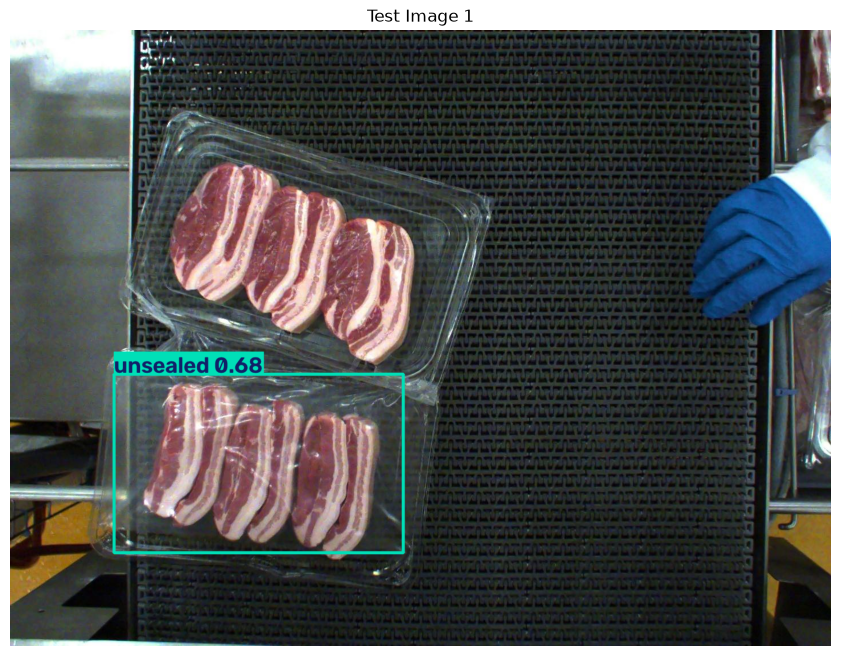

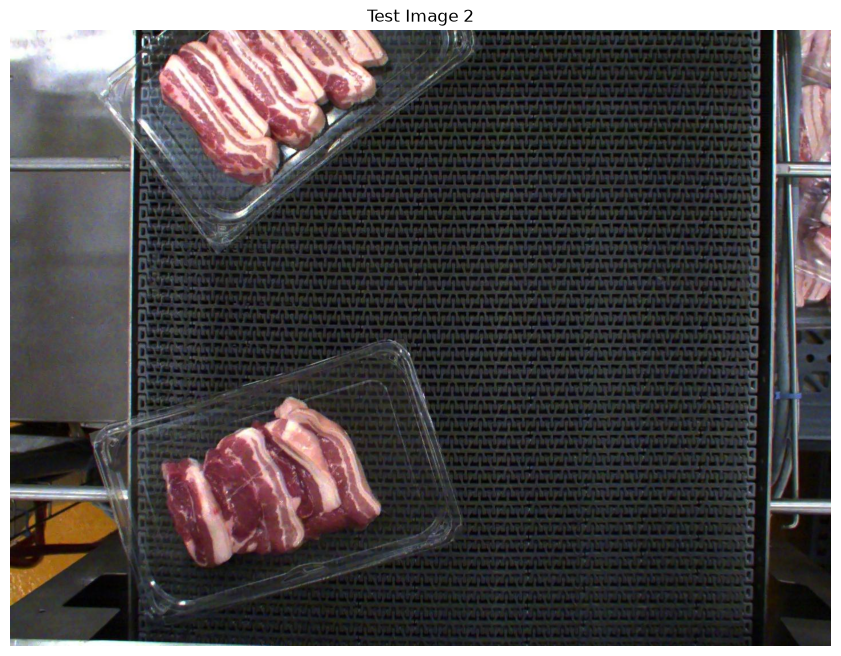

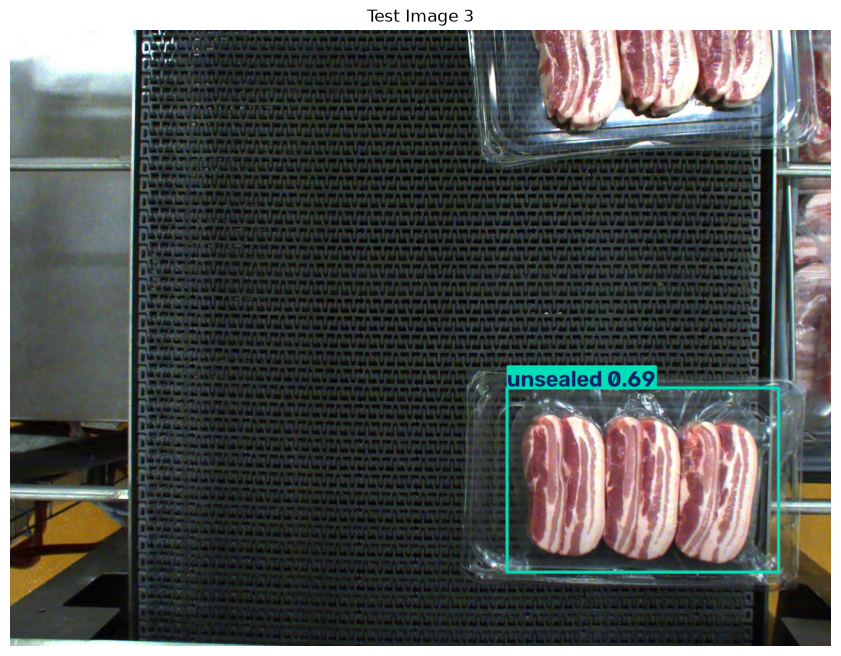

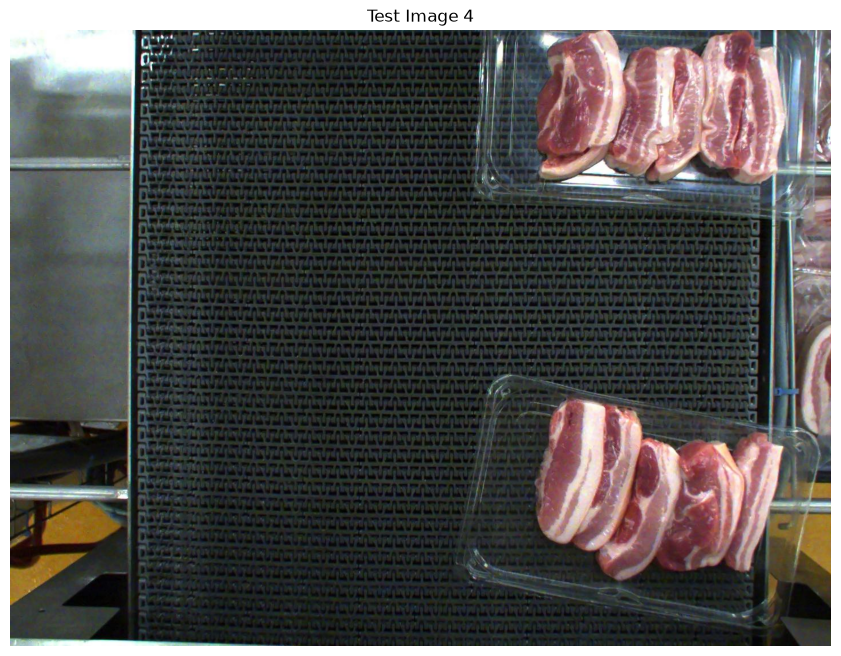

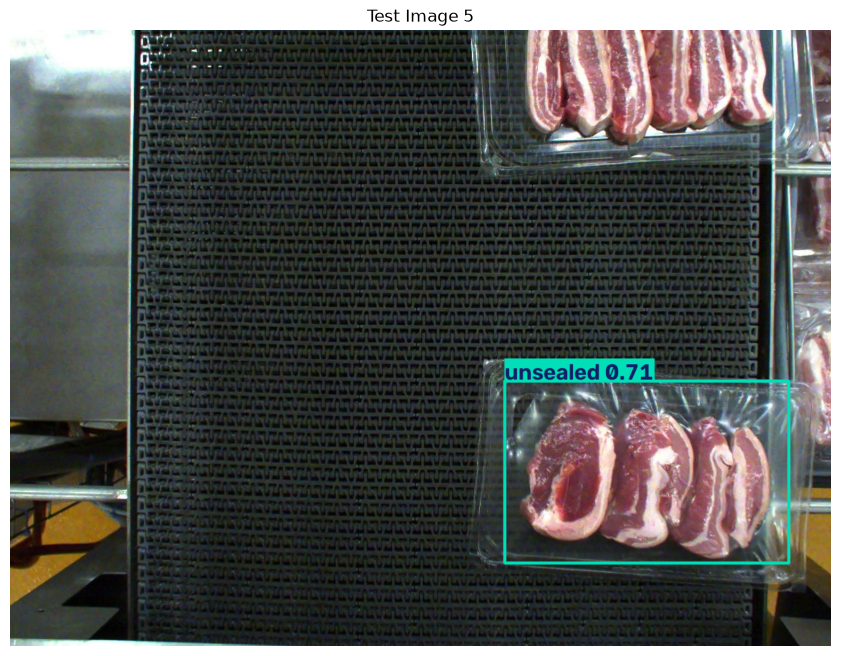

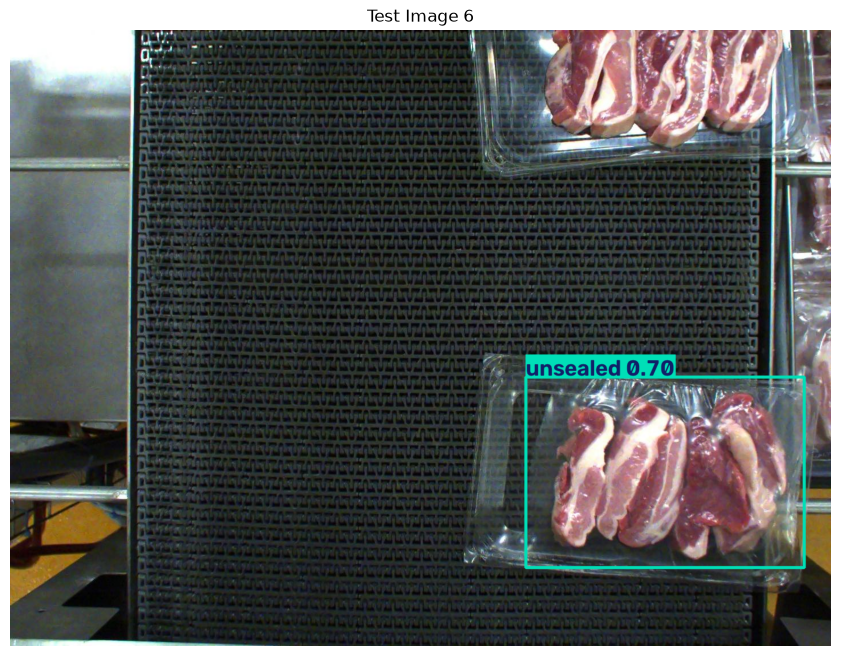

In [ ]:
# Use the final trained model
final_model = improved_best

# Select images from the test dataset
test_images = sorted(
    (YOLO_DIR / "images" / "test").glob("*.jpg")
)

# Display the first 6 images
sample_images = test_images[:6]

predictions = final_model.predict(
    source=[str(p) for p in sample_images],
    conf=0.30,
    imgsz=640,
    device=0,
    verbose=False
)

for i, prediction in enumerate(predictions):

    annotated_image = prediction.plot()

    plt.figure(figsize=(12, 8))
    plt.imshow(
        cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
    )
    plt.title(f"Test Image {i+1}")
    plt.axis("off")
    plt.show()

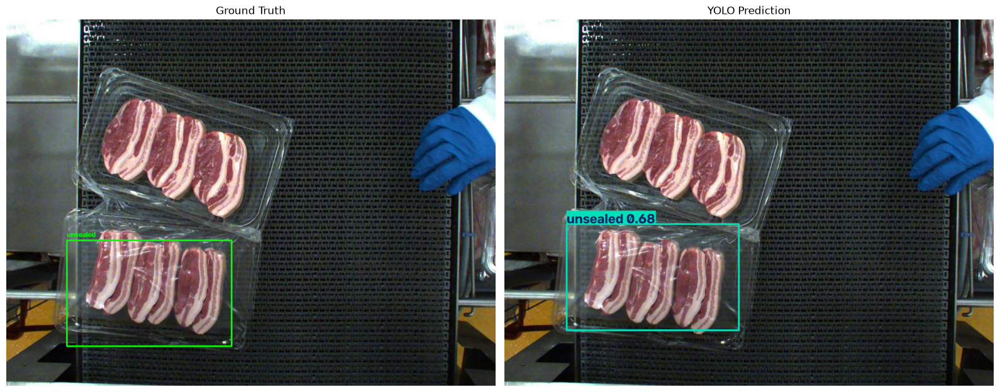

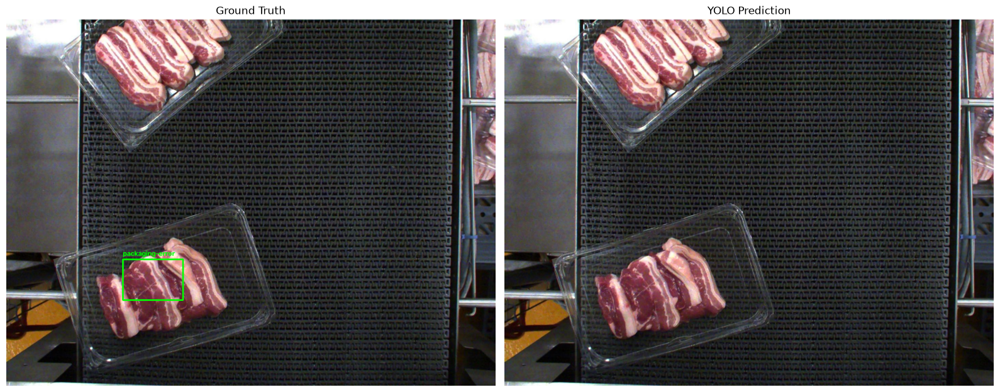

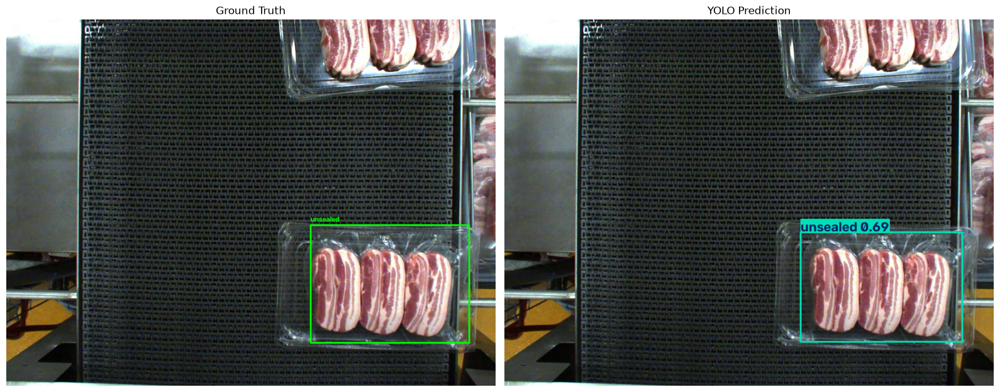

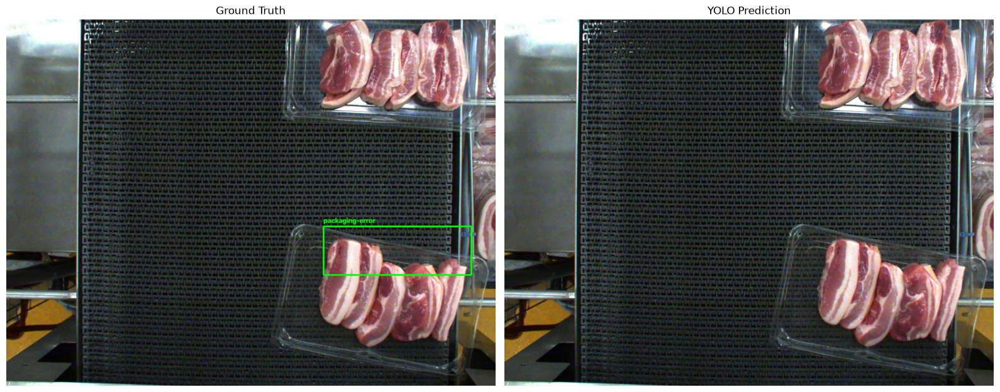

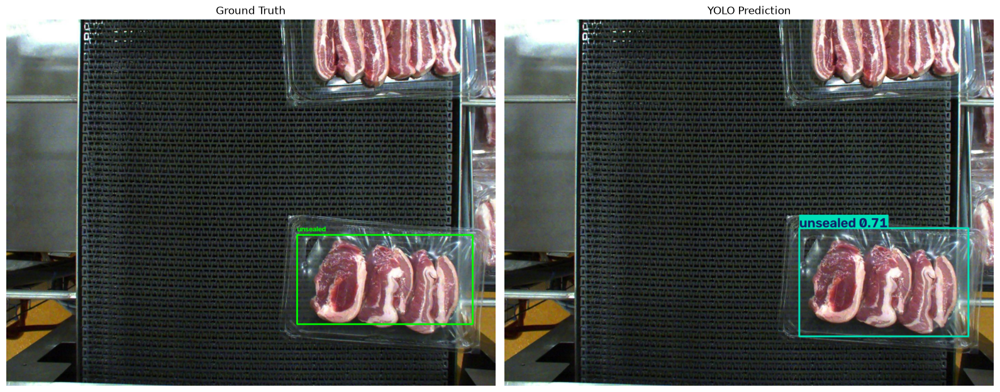

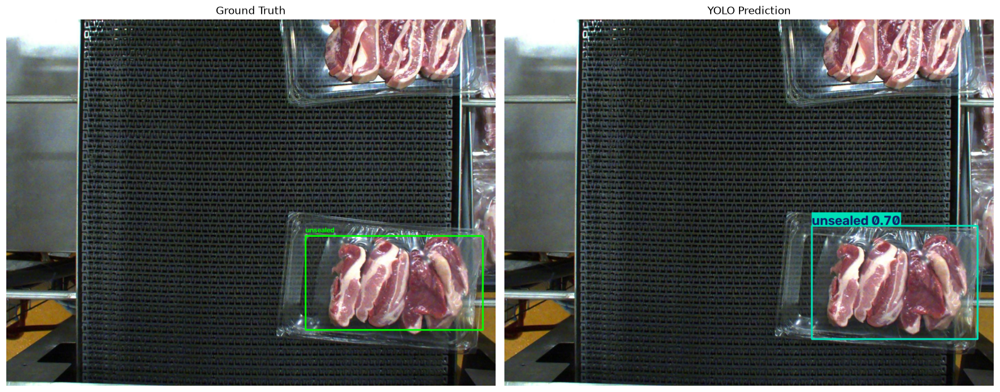

In [ ]:
for image_path, prediction in zip(sample_images, predictions):

    # Ground-truth image with YOLO-format annotations
    image = cv2.imread(str(image_path))
    ground_truth_image = image.copy()

    label_path = (
        YOLO_DIR / "labels" / "test" /
        f"{image_path.stem}.txt"
    )

    height, width = image.shape[:2]

    if label_path.exists():
        for line in label_path.read_text().splitlines():

            class_id, xc, yc, bw, bh = map(float, line.split())

            x1 = int((xc - bw / 2) * width)
            y1 = int((yc - bh / 2) * height)
            x2 = int((xc + bw / 2) * width)
            y2 = int((yc + bh / 2) * height)

            cv2.rectangle(
                ground_truth_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            cv2.putText(
                ground_truth_image,
                class_names[int(class_id)],
                (x1, max(20, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

    predicted_image = prediction.plot()

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(
        cv2.cvtColor(ground_truth_image, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Ground Truth")

    axes[1].imshow(
        cv2.cvtColor(predicted_image, cv2.COLOR_BGR2RGB)
    )
    axes[1].set_title("YOLO Prediction")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

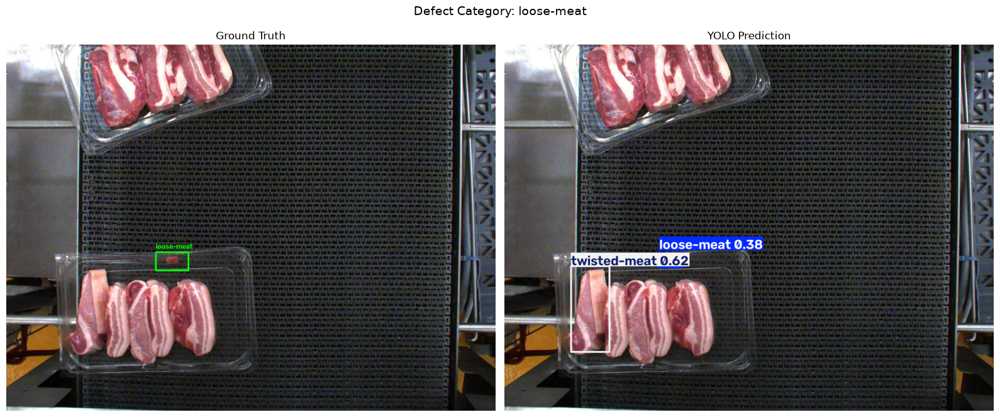

Saved: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\figures\loose-meat_comparison.png


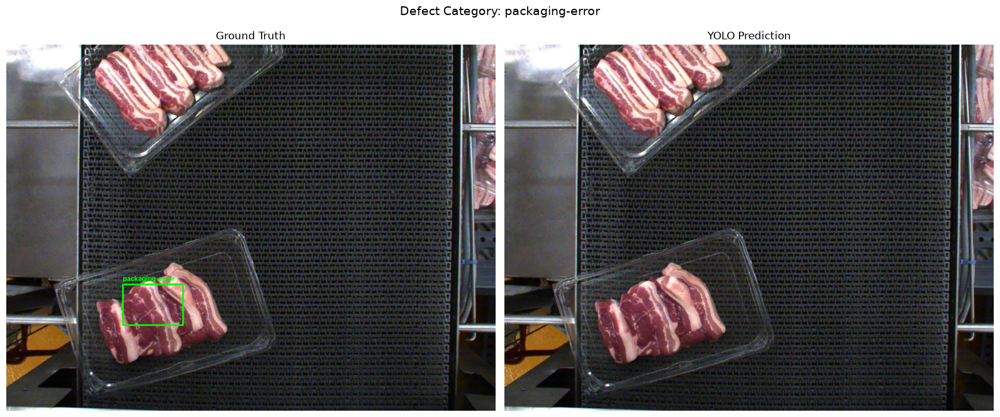

Saved: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\figures\packaging-error_comparison.png


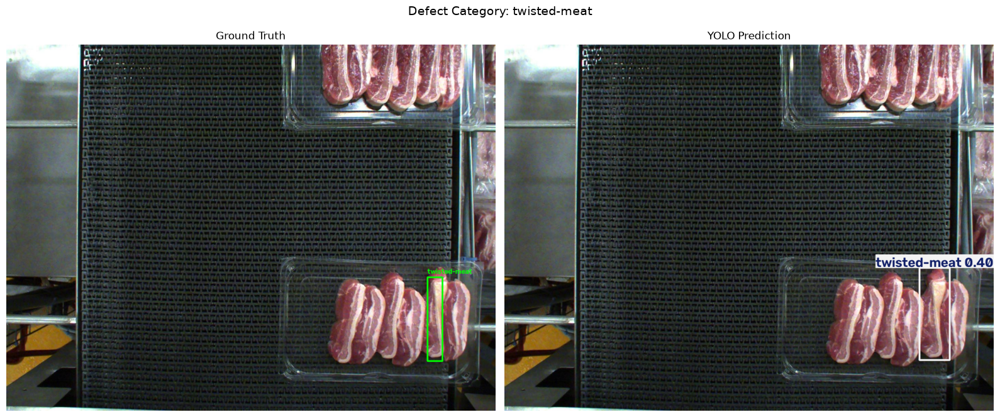

Saved: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\figures\twisted-meat_comparison.png


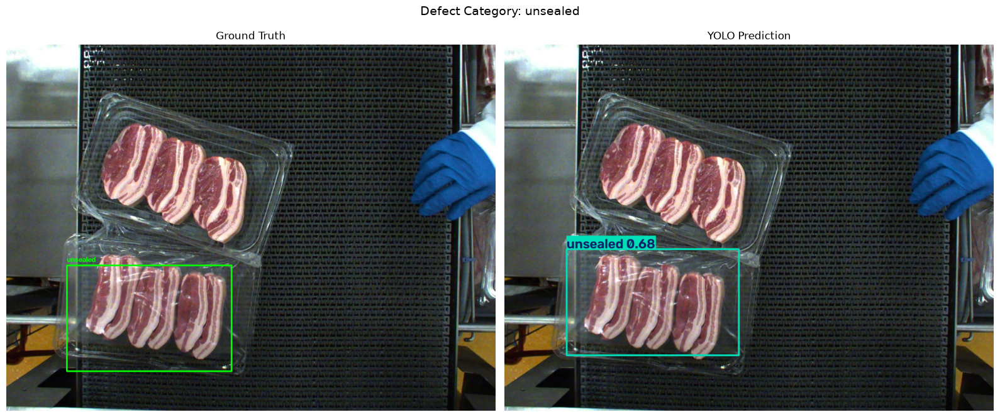

Saved: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\results\figures\unsealed_comparison.png
Skipping wrinkle: no test examples


In [ ]:
FIGURE_DIR = PROJECT_DIR / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for class_id, class_name in enumerate(class_names):

    available_images = images_by_class[class_id]

    if not available_images:
        print(f"Skipping {class_name}: no test examples")
        continue

    image_path = available_images[0]

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    ground_truth_image = image.copy()
    height, width = image.shape[:2]

    # Load ground-truth bounding boxes
    label_path = (
        YOLO_DIR / "labels" / "test" /
        f"{image_path.stem}.txt"
    )

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        cls, xc, yc, bw, bh = map(float, line.split())

        x1 = int((xc - bw / 2) * width)
        y1 = int((yc - bh / 2) * height)
        x2 = int((xc + bw / 2) * width)
        y2 = int((yc + bh / 2) * height)

        cv2.rectangle(
            ground_truth_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        cv2.putText(
            ground_truth_image,
            class_names[int(cls)],
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    # Generate predictions using frozen final model
    prediction = improved_best.predict(
        source=str(image_path),
        conf=0.30,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    predicted_image = prediction.plot()

    # Create comparison figure
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(
        cv2.cvtColor(
            ground_truth_image,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[0].set_title("Ground Truth")

    axes[1].imshow(
        cv2.cvtColor(
            predicted_image,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[1].set_title("YOLO Prediction")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Defect Category: {class_name}",
        fontsize=14
    )

    plt.tight_layout()

    # Save high-resolution figure
    output_path = (
        FIGURE_DIR / f"{class_name}_comparison.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)